# 2017→2024 — Sparse Mixture of Experts (MoE)

**Papers:** Noam Shazeer et al., *"Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer"* (2017); Fedus, Zoph & Shazeer, *Switch Transformer* (2021); Jiang et al., *Mixtral of Experts* (2024); DeepSeek-MoE / DeepSeek-V3 (2024).

Replace one big feed-forward layer by $E$ smaller **experts** and a **router** that sends each token to only the top-$k$:

$$y = \sum_{i \in \text{TopK}(g(x))} \operatorname{softmax}(g(x))_i\; \text{Expert}_i(x)$$

So total parameters grow with $E$ while compute per token grows only with $k$. Mixtral 8×7B has ~47B parameters but uses ~13B per token. Most frontier LLMs of 2024–2026 are MoEs (DeepSeek-V3, Qwen3-MoE, Llama 4, gpt-oss, Kimi K2).

**The catch: load balancing.** A router left alone tends to collapse onto a few experts. The Switch Transformer auxiliary loss
$$\mathcal L_{\text{bal}} = E\sum_{i=1}^{E} f_i\,P_i$$
($f_i$ = fraction of tokens sent to expert $i$, $P_i$ = mean router probability for $i$) is minimised by a uniform split. (DeepSeek-V3 instead uses a bias-based, loss-free balancing method.)

To make routing easy to see, we use an MoE classifier on digits. In an LLM, every *token* is routed this way inside each Transformer block.

![Diagram: Mixture of experts (Shazeer et al., 2017; Switch, 2021; DeepSeek-V3, 2024)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/64_2023_mixture_of_experts.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = load_digits_tensors()
Xtr, Xte, ytr, yte = Xtr.flatten(1).to(device), Xte.flatten(1).to(device), ytr.to(device), yte.to(device)

coef=0.0: test acc 0.975 | load per expert: [0.07 0.12 0.24 0.02 0.05 0.19 0.3  0.  ]
coef=0.05: test acc 0.972 | load per expert: [0.11 0.13 0.13 0.12 0.14 0.13 0.13 0.12]


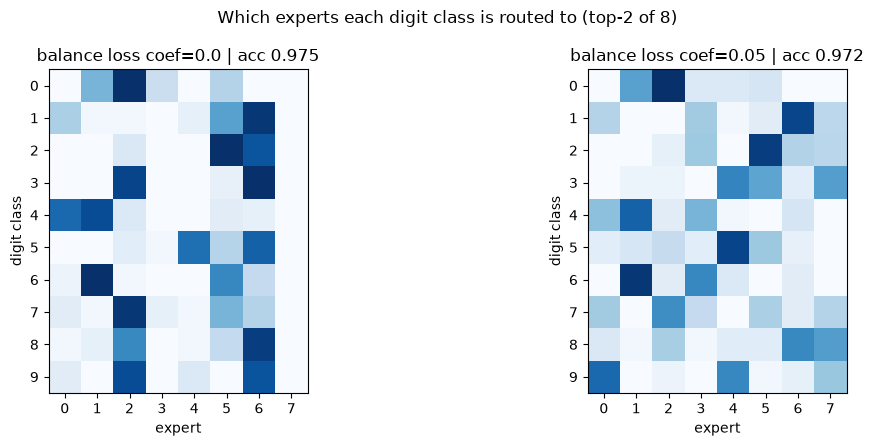

In [3]:
class MoE(nn.Module):
    def __init__(self, d, d_ff, n_experts=8, k=2):
        super().__init__()
        self.k, self.E = k, n_experts
        self.router = nn.Linear(d, n_experts, bias=False)
        self.w1 = nn.Parameter(torch.randn(n_experts, d, d_ff) / math.sqrt(d))        # experts stored as batched weights
        self.w2 = nn.Parameter(torch.randn(n_experts, d_ff, d) / math.sqrt(d_ff))

    def forward(self, x):
        probs = self.router(x).softmax(-1)                                            # (N, E)
        topv, topi = probs.topk(self.k, -1)
        gates = topv / topv.sum(-1, keepdim=True)                                     # renormalise over the chosen k
        out = torch.zeros_like(x)
        for e in range(self.E):                                                       # dispatch -> compute -> combine
            tok, slot = torch.where(topi == e)
            if len(tok) == 0: continue
            h = F.gelu(x[tok] @ self.w1[e]) @ self.w2[e]
            out.index_add_(0, tok, h * gates[tok, slot, None])
        # Switch-Transformer load-balancing loss
        f = F.one_hot(topi, self.E).float().sum(1).mean(0) / self.k                   # fraction of assignments per expert
        P = probs.mean(0)
        self.aux_loss = self.E * (f * P).sum()
        self.last_assign = topi.detach()
        return out

class MoEClassifier(nn.Module):
    def __init__(self, d=64, n_experts=8, k=2):
        super().__init__()
        self.inp = nn.Linear(64, d); self.norm = nn.LayerNorm(d)
        self.moe = MoE(d, 128, n_experts, k); self.head = nn.Linear(d, 10)
    def forward(self, x):
        h = F.gelu(self.inp(x))
        return self.head(h + self.moe(self.norm(h)))

def train(balance_coef, steps=2500):
    seed_everything(0)
    m = MoEClassifier().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    for s in range(steps):
        idx = torch.randint(0, len(Xtr), (128,), device=device)
        loss = F.cross_entropy(m(Xtr[idx]), ytr[idx]) + balance_coef * m.moe.aux_loss
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        acc = (m(Xte).argmax(1) == yte).float().mean().item()
        usage = torch.zeros(10, 8)
        for c in range(10):
            m(Xte[yte == c]); usage[c] = torch.bincount(m.moe.last_assign.flatten(), minlength=8).float().cpu()
    return m, acc, usage

results = {coef: train(coef) for coef in [0.0, 0.05]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (coef, (m, acc, usage)) in zip(axes, results.items()):
    ax.imshow(usage / usage.sum(1, keepdim=True), cmap="Blues")
    ax.set(xlabel="expert", ylabel="digit class", title=f"balance loss coef={coef} | acc {acc:.3f}")
    ax.set_xticks(range(8)); ax.set_yticks(range(10))
    share = usage.sum(0) / usage.sum()
    print(f"coef={coef}: test acc {acc:.3f} | load per expert: {np.round(share.numpy(), 2)}")
plt.suptitle("Which experts each digit class is routed to (top-2 of 8)"); plt.tight_layout(); plt.show()

## Compute vs. capacity
Each token touches only $k/E$ of the expert parameters.

In [4]:
m = results[0.05][0]
expert_params = m.moe.w1.numel() + m.moe.w2.numel()
print(f"total expert parameters: {expert_params:,} | active per token (k=2 of 8): {expert_params * 2 // 8:,}")

total expert parameters: 131,072 | active per token (k=2 of 8): 32,768
